In [44]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.fft import rfft, rfftfreq, irfft

import scipy.signal

plt.rcParams["figure.figsize"] = (12,8)


In [45]:
df_L05S03_L05S03 = pd.read_csv("data/high_stat_2/stim_L05S03_recv_L05S03.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L05S04_L05S04 = pd.read_csv("data/high_stat_2/stim_L05S04_recv_L05S04.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L05S05_L05S05 = pd.read_csv("data/high_stat_2/stim_L05S05_recv_L05S05.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L05S05_L05S04 = pd.read_csv("data/high_stat_2/stim_L05S05_recv_L05S04.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L05S05_L15S05 = pd.read_csv("data/high_stat_2/stim_L05S05_recv_L15S05.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])

df_L45S05_L45S05 = pd.read_csv("data/high_stat_2/stim_L45S05_recv_L45S05.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L45S05_L45S04 = pd.read_csv("data/high_stat_2/stim_L45S05_recv_L45S04.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L45S05_L45S03 = pd.read_csv("data/high_stat_2/stim_L45S05_recv_L45S03.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])
df_L45S05_L55S05 = pd.read_csv("data/high_stat_2/stim_L45S05_recv_L55S05.csv", skiprows=[0,1,2], encoding="utf-8", header = None, names = ['freq', 's11_m', 's11_p', "s21_m", "s21_p"])


dfs = { "L05S03_L05S03": df_L05S03_L05S03,
        "L05S04_L05S04": df_L05S04_L05S04,
        "L05S05_L05S05": df_L05S05_L05S05,
        "L05S05_L05S04": df_L05S05_L05S04,
        "L05S05_L15S05": df_L05S05_L15S05,
        "L45S05_L45S05": df_L45S05_L45S05,
        "L45S05_L45S04": df_L45S05_L45S04,
        "L45S05_L45S03": df_L45S05_L45S03,
        "L45S05_L55S05": df_L45S05_L55S05, }

keys_thru = ["L05S03_L05S03", "L05S04_L05S04", "L05S05_L05S05", "L45S05_L45S05"]
keys_xtalk = ["L05S05_L05S04", "L05S05_L15S05", "L45S05_L45S04", "L45S05_L45S03", "L45S05_L55S05"]

for key in dfs:
    dft = dfs[key]
    dft['s11_p'] = dft['s11_p'] / 180.0 * np.pi
    dft['s11_p'] = np.unwrap(dft['s11_p'])

    dft['s21_p'] = dft['s21_p'] / 180.0 * np.pi
    dft['s21_p'] = np.unwrap(dft['s21_p'])

    dft['s11_c'] = dft['s11_m'] * np.exp(1j * dft['s11_p'])
    dft['s21_c'] = dft['s21_m'] * np.exp(1j * dft['s21_p'])





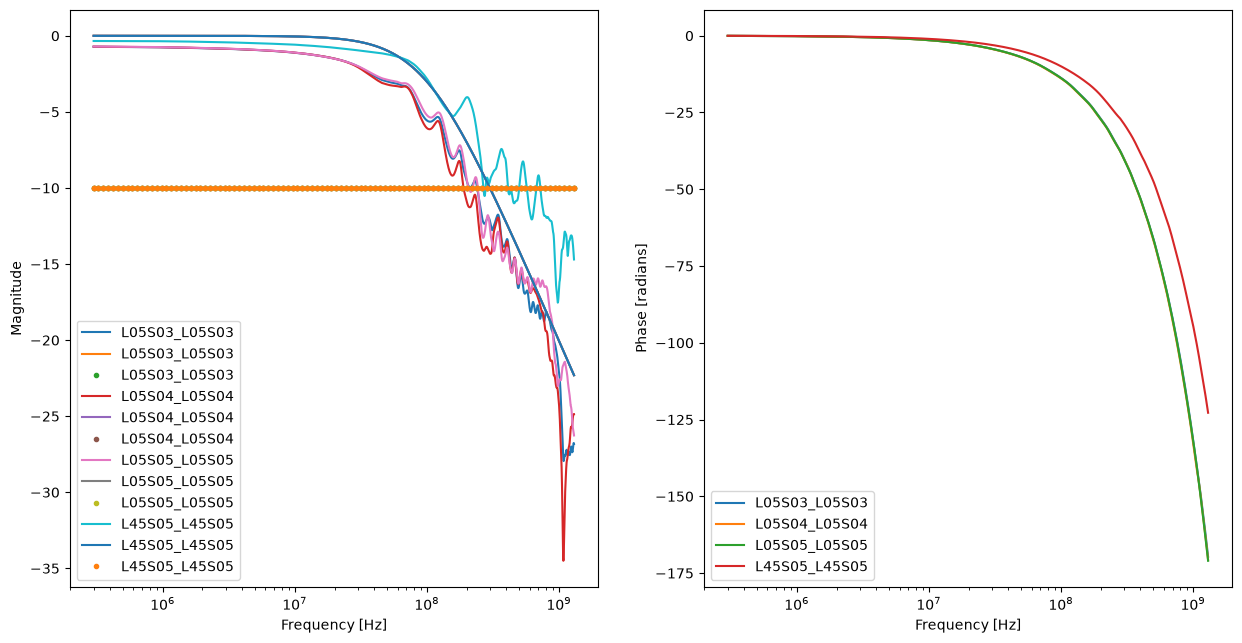

In [ ]:
def lowpass_mag(freq, f_c, offset):
    return 20*np.log10(1/np.sqrt(1+(freq/np.power(10, f_c))**2)) + offset

fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(15, 7.5))

for key in keys_thru:
    dft = dfs[key]
    ax1.plot(dft['freq'], dft['s21_m'], label = key)

    ax1.plot(dft['freq'], lowpass_mag(dft['freq'], 1E8, 0), label = key)

    xx = np.logspace(np.log10(dft['freq'].min()), np.log10(dft['freq'].max()), 100)
    ax1.plot(xx, np.ones(xx.shape)*-10, '.', label = key)
ax1.set_xlabel('Frequency [Hz]')
ax1.set_ylabel('Magnitude')


    
ax1.legend()
ax1.set_xscale('log')

for key in keys_thru:
    dft = dfs[key]
    ax2.plot(dft['freq'], dft['s21_p'], label = key)
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Phase [radians]')

ax2.legend()
ax2.set_xscale('log')

Text(0.5, 1.0, 'Phase Spectrum')

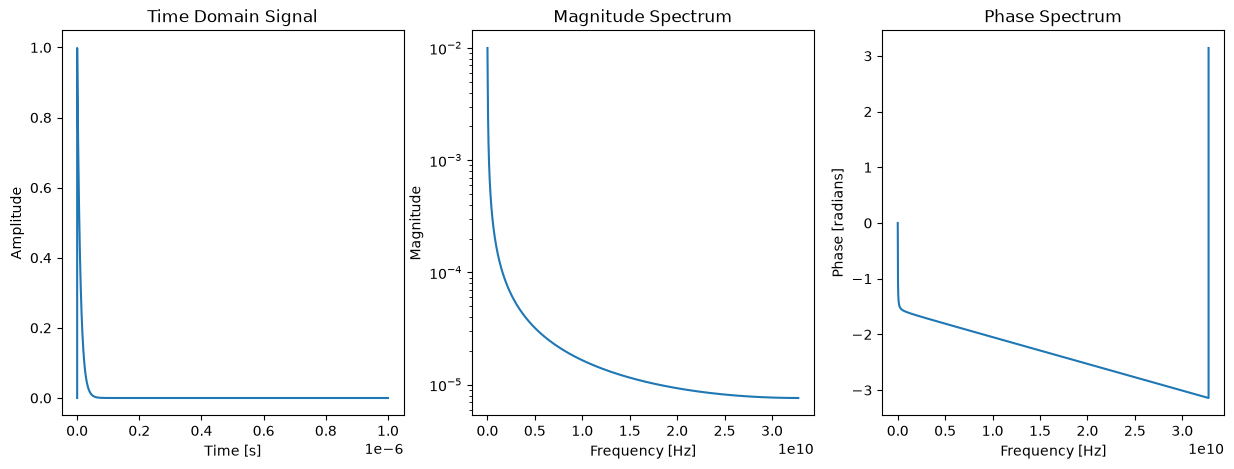

In [19]:
N, tau = 2**16, 1E-6 # number of samples and signal duration in seconds
T = tau / N  # sampling interval
t = np.arange(N) * T  # sample times

x = [0 if t == 0 else np.exp(-t/10E-9) for t in t]
#x = [1 if t == 0 else 0 for t in t]
#x = np.sin(2 * np.pi * 50E6 * t)  # 50 Hz sine wave

f = rfftfreq(N, T)  # frequency values

X = rfft(x) / N

X_mag = abs(X)  # Magnitude spectrum
X_phase = np.angle(X)



fig, [ax0, ax1, ax2] = plt.subplots(1,3, figsize=(15,5))

ax0.plot(t, x)
ax0.set_xlabel('Time [s]')
ax0.set_ylabel('Amplitude')
ax0.set_title('Time Domain Signal')


ax1.plot(f, X_mag)
ax1.set_xlabel('Frequency [Hz]')
ax1.set_ylabel('Magnitude')
ax1.set_title('Magnitude Spectrum')
ax1.set_yscale('log')

ax2.plot(f, X_phase)
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Phase [radians]')
ax2.set_title('Phase Spectrum')



In [20]:
x_f = {}

for key in dfs:
    dft = dfs[key]

    filter_freq = dft['freq']
    filter_mag = dft['s21_m']
    filter_phase = dft['s21_p']

    filter_interp_mag = np.interp(f, filter_freq, filter_mag)
    filter_interp_phase = np.interp(f, filter_freq, filter_phase)

    filter_c = 10**(filter_interp_mag/10) * np.exp(1j * filter_interp_phase)

    X_f = X * filter_c
  
    x_f[key] = irfft(X_f)*N

    


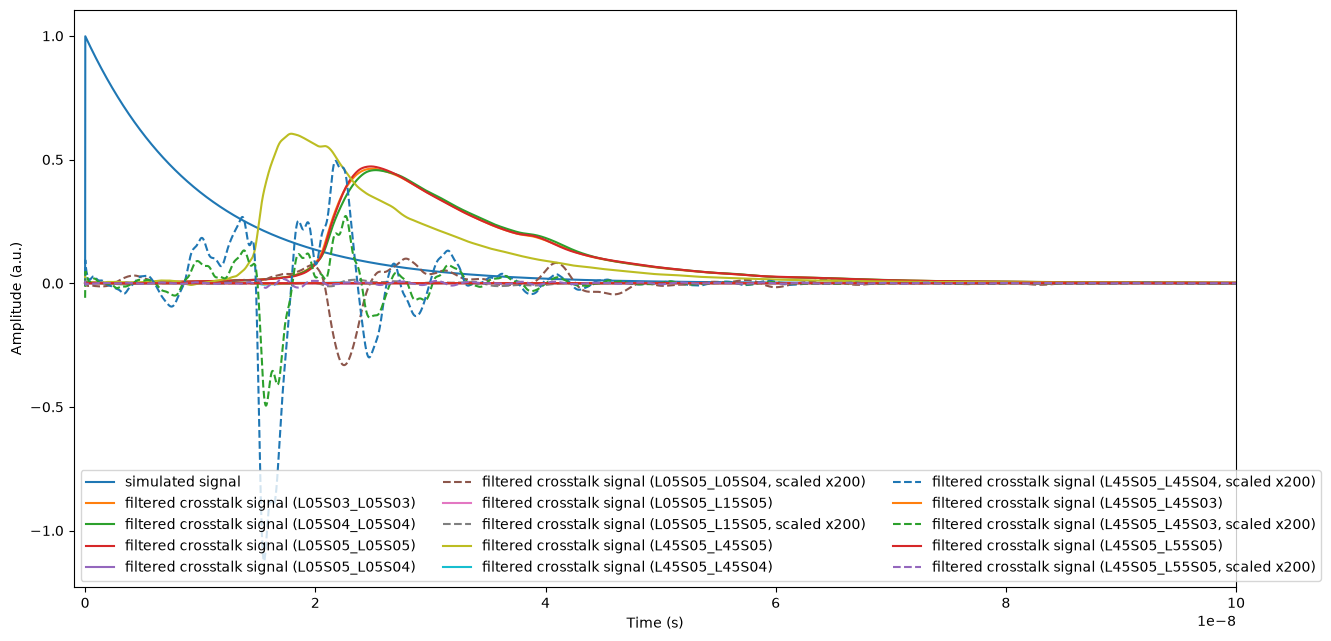

In [26]:
plt.figure(figsize=(15, 7.5))


plt.plot(t, x, label='simulated signal')

for key in x_f:
    plt.plot(t, x_f[key], label=f'filtered crosstalk signal ({key})')
    # scaled version for visibility
    if key in keys_xtalk:
        plt.plot(t, x_f[key]*200,  '--', label=f'filtered crosstalk signal ({key}, scaled x200)')

plt.xlim(-1E-9, 1E-7)

plt.xlabel('Time (s)')
plt.ylabel('Amplitude (a.u.)')

plt.legend(ncol=3)
# plt.yscale('log')
#plt.ylim(-1E-2, 1E-2)


